# 3.7 — Resumen del análisis exploratorio

Esta libreta resume las libretas de EDA `3.0` a `3.6`. Cada una responde una
pregunta sobre el panel integrado de Hermosillo (72 meses y 313 semanas
epidemiológicas, 2015–2020):

| Libreta | Pregunta | Hallazgo principal |
|---------|----------|--------------------|
| `3.0` Integración | ¿Cómo quedó el panel? | Una fila por semana (313) o por mes (72) con todas las capas |
| `3.1` Datos faltantes | ¿Qué falta? | PM10/O3 con huecos por falla de la estación; PM2.5 sin datos desde 2018 |
| `3.2` Outliers | ¿Qué semanas son raras? | 7 semanas extremas por consenso, todas ligadas a eventos reales |
| `3.3` Relaciones | ¿Qué mueve los casos? | **El calendario**: el mes explica ~79 % de la variación |
| `3.4` Correlación | ¿El clima causa los casos? | Las correlaciones crudas eran la época del año; solo queda una señal débil del frío rezagado |
| `3.5` Reducción dimensional | ¿Hay grupos ocultos? | PCA/t-SNE agrupan por temporada, no por clima extremo |
| `3.6` Marginación urbana | ¿Las zonas marginadas sufren más? | No en las colonias observables; las 12 más marginadas no tienen unidad que las observe |

## Preparación

In [11]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parent.parent))  # raíz del proyecto

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from sonora_health_climate_eda.config import EXTERNAL_DATA_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR

P = PROCESSED_DATA_DIR
GRIS, AZUL = "#9aa4b1", "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Integración del panel (`3.0`)

Las seis capas procesadas se unen en un **panel semanal** (la unidad
epidemiológica) y un **panel mensual**. Cada fila junta casos de IRA,
temperatura, calor extremo, sequía, aire y marginación, más dos banderas:
`anio_atipico` (2020, por COVID) y semanas con ola de calor y sequía a la vez.

In [12]:
semanal = pd.read_parquet(P / "panel_eda_semanal.parquet")
mensual = pd.read_parquet(P / "panel_eda.parquet")

print(f"Panel semanal: {semanal.shape[0]} semanas x {semanal.shape[1]} columnas")
print(f"Panel mensual: {mensual.shape[0]} meses x {mensual.shape[1]} columnas")
print(f"Periodo: {semanal['fecha_semana'].min():%Y-%m-%d} a {semanal['fecha_semana'].max():%Y-%m-%d}")
semanal.head()

Panel semanal: 313 semanas x 11 columnas
Panel mensual: 72 meses x 13 columnas
Periodo: 2015-01-04 a 2020-12-27


,fecha_semana,casos_ira_total,tmax_media_sem,dias_ola_calor_p95,humedad_rel_media,severidad_sequia,pm10_ugm3,o3_max8h_ppb,IM,semana_ola_calor_p95_y_sequia,anio_atipico
0,2015-01-04,5463,26.885714,0,37.571429,NaN,60.53,30.22,51.512968,False,False
1,2015-01-11,5898,24.142857,0,48.857143,0.0,54.11,27.16,51.512968,False,False
2,2015-01-18,6160,26.400000,0,35.714286,0.0,57.04,32.46,51.512968,False,False
3,2015-01-25,6515,24.142857,0,68.571429,0.0,24.00,24.15,51.512968,False,False
4,2015-02-01,5914,26.685714,0,65.142857,0.0,34.86,36.90,51.664586,False,False


## 2. Datos faltantes (`3.1`)

Cada variable tiene un "hueco" distinto. Los más importantes:

- **Sequía:** el monitor empezó a fines de 2015.
- **Aire (PM10/O3):** fallas largas de la estación ERNO; solo se rellenaron
  huecos cortos y quedaron marcados.
- **PM2.5:** deja de medirse a mediados de 2018, por eso se excluyó del
  análisis de relaciones.

In [13]:
faltantes = semanal.drop(columns=["fecha_semana", "semana_ola_calor_p95_y_sequia", "anio_atipico"]).isna()
faltantes.sum().rename("semanas sin dato (de 313)").sort_values(ascending=False)

o3_max8h_ppb          34
pm10_ugm3             27
severidad_sequia       1
casos_ira_total        0
tmax_media_sem         0
dias_ola_calor_p95     0
humedad_rel_media      0
IM                     0
Name: semanas sin dato (de 313), dtype: int64

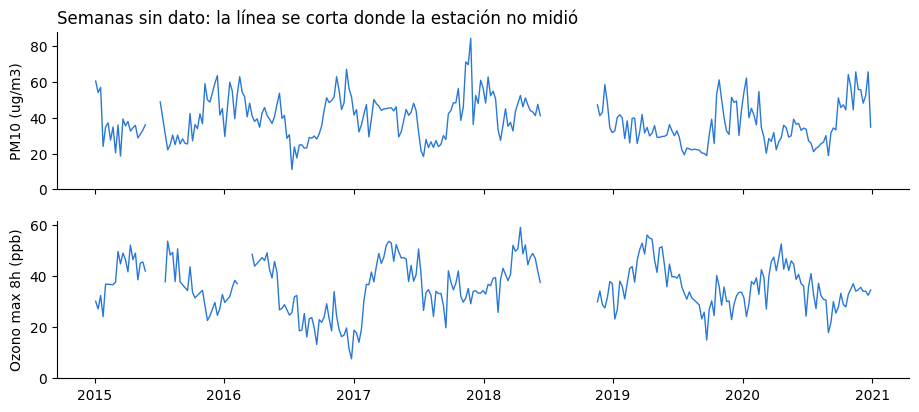

In [14]:
# Los huecos se ven mejor en la propia serie: donde se corta la línea, no hay dato.
fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
for ax, (col, titulo) in zip(axes, [("pm10_ugm3", "PM10 (ug/m3)"), ("o3_max8h_ppb", "Ozono max 8h (ppb)")]):
    ax.plot(semanal["fecha_semana"], semanal[col], color=AZUL, lw=1)
    ax.set_ylabel(titulo)
    ax.set_ylim(bottom=0)
axes[0].set_title("Semanas sin dato: la línea se corta donde la estación no midió", loc="left")
plt.show()

## 3. Outliers (`3.2`)

Cuatro técnicas marcan semanas raras (IQR, Z-score, Isolation Forest y LOF).
El resultado se guardó en `panel_eda_outliers_semanal.parquet`. Solo **7
semanas** son marcadas por la mayoría de técnicas (`outlier_consenso`) y
todas corresponden a eventos reales, así que **no se borraron ni se
alteraron**: se dejaron con bandera.

In [15]:
outliers = pd.read_parquet(P / "panel_eda_outliers_semanal.parquet")
print("Semanas marcadas por cada técnica:")
print(outliers[["outlier_iqr", "outlier_zscore", "outlier_estacional",
                "outlier_iforest", "outlier_lof", "outlier_consenso"]].sum())

outliers.loc[outliers["outlier_consenso"], ["fecha_semana", "casos_ira_total", "n_tecnicas"]]

Semanas marcadas por cada técnica:
outlier_iqr            3
outlier_zscore         2
outlier_estacional    43
outlier_iforest       16
outlier_lof           16
outlier_consenso       7
dtype: int64


,fecha_semana,casos_ira_total,n_tecnicas
103,2016-12-25,4434,5
151,2017-11-26,5262,5
162,2018-02-11,5152,3
171,2018-04-15,3468,2
246,2019-09-22,3673,2
295,2020-08-30,665,3
312,2020-12-27,1020,2


## 4. Relaciones: el calendario manda (`3.3`)

Los casos casi se **triplican del verano al invierno** (~1,900 por semana en
julio a ~6,200 en enero), todos los años. Solo con saber **en qué mes estamos**
se explica el **79 %** de las subidas y bajadas semanales.

El problema: **cada variable ambiental tiene su propia temporada** (calor en
verano, sequía en primavera, PM10 en invierno). En crudo, todo parece
relacionado con todo.

In [16]:
pre2020 = semanal[~semanal["anio_atipico"].astype(bool)].copy()
pre2020["mes"] = pre2020["fecha_semana"].dt.month

# ¿Cuánto explica el mes? R2 = varianza entre promedios de cada mes / varianza total
promedios_mes = pre2020.groupby("mes")["casos_ira_total"].transform("mean")
r2 = 1 - pre2020["casos_ira_total"].var() ** -1 * (pre2020["casos_ira_total"] - promedios_mes).var()
print(f"El mes del año explica el {r2:.0%} de la variación de los casos")

promedios_mes.agg(["min", "max"]).round(0)

El mes del año explica el 79% de la variación de los casos


min    1898.0
max    6166.0
Name: casos_ira_total, dtype: float64

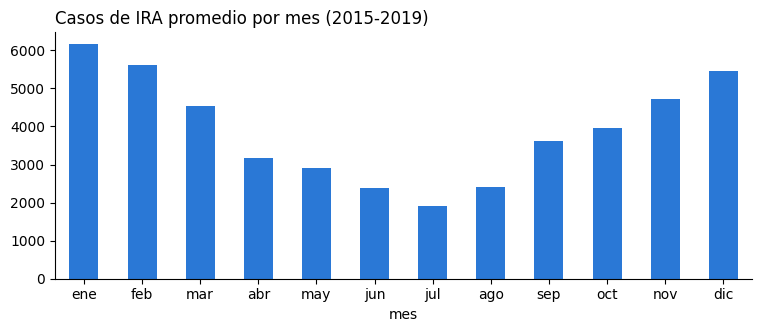

In [17]:
# Promedio de casos por mes del año: el pico de enero y el valle de julio
fig, ax = plt.subplots(figsize=(9, 3.2))
pre2020.groupby("mes")["casos_ira_total"].mean().plot(kind="bar", color=AZUL, ax=ax)
ax.set_xticklabels(["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"], rotation=0)
ax.set_title("Casos de IRA promedio por mes (2015-2019)", loc="left")
plt.show()

## 5. Correlación: era la época del año (`3.4`)

Para separar al clima del calendario, cada semana se compara con **lo normal
de su mes** (se le resta el promedio de ese mes). Al hacerlo, las
correlaciones fuertes se **desvanecen**: la temperatura baja de −0.78 a
−0.02 y el PM10 de +0.49 a +0.12.

Solo quedan señales débiles: una semana **más fría de lo normal** trae un
pequeño aumento de casos **3 a 5 semanas después** (−0.15 con 5 semanas de
rezago), y el ozono deja una asociación frágil que depende de lecturas
dudosas de 2016.

In [18]:
base = semanal[~semanal["anio_atipico"].astype(bool)].reset_index(drop=True)
base["mes"] = base["fecha_semana"].dt.month

VARIABLES = ["tmax_media_sem", "humedad_rel_media", "severidad_sequia", "pm10_ugm3", "o3_max8h_ppb"]
NOMBRE = {"casos_ira_total": "Casos de IRA", "tmax_media_sem": "Temperatura max.", "humedad_rel_media": "Humedad",
          "severidad_sequia": "Sequia", "pm10_ugm3": "PM10", "o3_max8h_ppb": "Ozono"}

# "Sin la epoca": cada valor menos el promedio de su mes del año
sin_epoca = base[["casos_ira_total"] + VARIABLES] - base.groupby("mes")[["casos_ira_total"] + VARIABLES].transform("mean")

tabla = pd.DataFrame({
    "datos originales": base[VARIABLES].corrwith(base["casos_ira_total"], method="spearman"),
    "sin la epoca": sin_epoca[VARIABLES].corrwith(sin_epoca["casos_ira_total"], method="spearman"),
}).rename(index=NOMBRE)
tabla.round(2)

,datos originales,sin la epoca
Temperatura max.,-0.78,-0.02
Humedad,0.01,-0.10
Sequia,-0.18,0.01
PM10,0.49,0.12
Ozono,-0.18,0.21


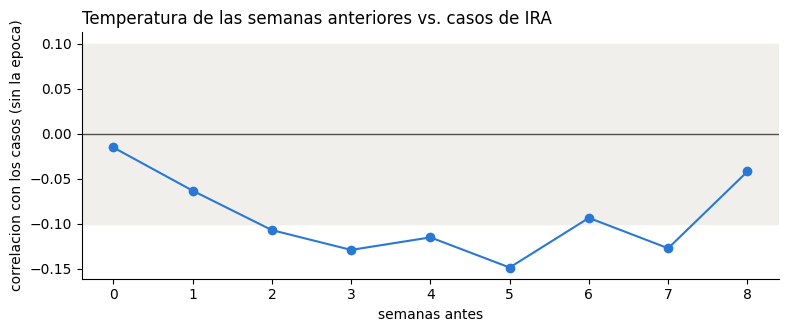

Rezago 5 semanas: -0.15 (la senal mas fuerte que sobrevive)


In [19]:
# La senal del frio: temperatura de k semanas atras vs. casos de hoy
rezagos = [sin_epoca["casos_ira_total"].corr(sin_epoca["tmax_media_sem"].shift(k), method="spearman")
           for k in range(9)]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(9), rezagos, marker="o", color=AZUL)
ax.axhspan(-0.1, 0.1, color="#f0efec")
ax.axhline(0, color="#52514e", lw=1)
ax.set_xticks(range(9))
ax.set_xlabel("semanas antes")
ax.set_ylabel("correlacion con los casos (sin la epoca)")
ax.set_title("Temperatura de las semanas anteriores vs. casos de IRA", loc="left")
plt.show()

print(f"Rezago 5 semanas: {rezagos[5]:+.2f} (la senal mas fuerte que sobrevive)")

## 6. Reducción de dimensionalidad (`3.5`)

PCA y t-SNE reducen el panel a dos dimensiones para buscar grupos. Lo que
aparece es la **temporada** (invierno vs. verano), no un grupo de "semanas de
clima extremo": el calor extremo y la sequía no forman un patrón propio que
coincida con más casos.

 ## 7. Marginación urbana (`3.6`)

Se cruzaron las 103 unidades médicas de CLUES con las 657 colonias del índice
de marginación de CONAPO — tras corregir a mano las 17 unidades con
coordenadas erróneas del catálogo, 91 clínicas cayeron dentro de una colonia
y la carga de casos (94 %) se repartió entre **63 colonias**.

**Resultado:** en las colonias observables, el grado de marginación no se
traduce en más casos ni en peor reacción al frío (la temporada pega igual a
todos). Pero **las 12 colonias más marginadas no tienen ninguna unidad que
reporte casos**: una brecha de acceso a la salud en sí misma.

In [20]:
colonias = gpd.read_file(INTERIM_DATA_DIR / "marginacion" / "colonias_marginacion_hermosillo.gpkg")
print(f"{len(colonias)} colonias de Hermosillo")
print(f"Las mas marginadas (Alto + Muy alto): {(colonias['GM_2020'].isin(['Alto', 'Muy alto'])).sum()}")
colonias["GM_2020"].value_counts().rename("colonias por grado de marginacion")

657 colonias de Hermosillo
Las mas marginadas (Alto + Muy alto): 12


GM_2020
Muy bajo    452
Bajo        159
Medio        34
Muy alto      8
Alto          4
Name: colonias por grado de marginacion, dtype: int64

## En resumen

- **El hallazgo principal es el calendario**: los casos casi se triplican en
  invierno y el mes explica ~79 % de la variación.
- Las correlaciones crudas del clima con los casos (−0.78 temperatura,
  +0.49 PM10) **eran estacionalidad compartida**: al quitar la época
  desaparecen.
- Solo sobrevive una **señal pequeña del frío anómalo** 3–5 semanas después,
  inconsistente entre años.
- **En las colonias observables no hay gradiente de marginación**; el
  hallazgo real es que las 12 colonias más marginadas no tienen unidad
  médica que las observe.
- Limitaciones a recordar: PM2.5 sin datos desde 2018, una sola estación de
  aire, huecos largos no rellenados y 2020 atípico por COVID.